In [1]:

from google.colab import files
enviados = files.upload()

Saving teste5.csv to teste5.csv
Saving teste4.csv to teste4.csv
Saving teste3.csv to teste3.csv
Saving teste2.csv to teste2.csv
Saving teste1.csv to teste1.csv


In [2]:

import os, shutil, pandas as pd
os.makedirs("dados", exist_ok=True)
os.makedirs("fig", exist_ok=True)
for f in os.listdir():
    if f.lower().endswith(".csv"):
        try:
            n = int(pd.read_csv(f, nrows=1)["teste"].iloc[0])
            shutil.move(f, f"dados/teste{n}.csv")
            print("ok:", f, "->", f"dados/teste{n}.csv")
        except Exception as e:
            print("ignorado:", f, "-", e)
faltam = [i for i in range(1, 6) if not os.path.exists(f"dados/teste{i}.csv")]
print("Todos os testes encontrados!" if not faltam else f"FALTAM os testes: {faltam} - envie de novo pela célula 1")

ok: teste3.csv -> dados/teste3.csv
ok: teste4.csv -> dados/teste4.csv
ok: teste5.csv -> dados/teste5.csv
ok: teste2.csv -> dados/teste2.csv
ok: teste1.csv -> dados/teste1.csv
Todos os testes encontrados!


In [3]:

"""Gera as figuras da seção de Avaliação do artigo (B + Splay).
Todas as figuras usam a mediana das 5 sementes. ganho = tempo(so_b) / tempo(versão)."""
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

D, F = "dados/", "fig/"
plt.rcParams.update({
    "font.family": "serif", "font.size": 9, "axes.titlesize": 9.5, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.linewidth": 0.6,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "legend.frameon": False, "savefig.bbox": "tight", "savefig.dpi": 300,
    "hatch.linewidth": 0.5, "hatch.color": "#2b2b2b",
})
W = 6.0  # largura do texto no template SBC (~15 cm)


COR = {"so_b": "#2a78d6", "so_splay": "#eb6834", "duas": "#1baf7a", "mista": "#eda100", "migra": "#e87ba4"}
HAT = {"so_b": "", "so_splay": "////", "duas": "", "mista": "....", "migra": "xxxx"}
NOME = {"so_b": "Apenas Árvore B", "so_splay": "Apenas Árvore Splay", "duas": "Duas árvores", "mista": "Mista (cap 4096)", "migra": "Migração"}
EDGE = "#2b2b2b"
NS = {10000: "n = 10 mil", 100000: "n = 100 mil", 1000000: "n = 1 milhão"}

def ler(t):
    return pd.read_csv(D + f"teste{t}.csv")

def medianas(d, chaves):
    return d.groupby(chaves).median(numeric_only=True)

def com_ganho(d, chaves):
    m = medianas(d, chaves + ["versao"]).reset_index()
    b = m[m.versao == "so_b"].set_index(chaves)["ns_por_op"]
    m["ganho"] = m.apply(lambda r: b.loc[tuple(r[c] for c in chaves)] / r.ns_por_op, axis=1)
    return m

def faixa_ruido(ax, horizontal=True):
    ax.axhspan(0.9, 1.1, color="#f0efec", zorder=0, lw=0)
    ax.axhline(1, color="#52514e", lw=0.9, zorder=1)

from matplotlib.ticker import FuncFormatter
VIRG = FuncFormatter(lambda v, p: f"{v:g}".replace(".", ","))
def br(v, d=2):
    return f"{v:.{d}f}".replace(".", ",")

def salvar(fig, nome):
    for ax in fig.axes:
        if ax.get_yscale() == "linear" and type(ax.yaxis.get_major_formatter()).__name__ == "ScalarFormatter":
            ax.yaxis.set_major_formatter(VIRG)
    fig.savefig(F + nome + ".pdf"); fig.savefig(F + nome + ".png"); plt.close(fig)

t1, t2, t3, t4, t5 = (ler(i) for i in range(1, 6))

# ---------------------------------------------------------------- Fig. 1

g1 = medianas(t1[t1.n == 1_000_000], ["carga", "versao"])
g5 = medianas(t5[t5.n == 1_000_000], ["carga", "versao"])
cargas = ["U", "Z0.8", "Z1.0", "Z1.2", "Z1.5"]
rot = ["U\n(s = 0)", "Z0.8", "Z1.0", "Z1.2", "Z1.5"]
def pega(carga, versao, col):
    g = g5 if carga == "Z1.0" else g1
    return g.loc[(carga, versao), col]
fig, axs = plt.subplots(1, 2, figsize=(W, 2.4))
for ax, col, tit in [(axs[0], "nos_visitados", "(a) Nós visitados por busca"),
                     (axs[1], "ns_por_op", "(b) Tempo por busca (ns)")]:
    x = np.arange(len(cargas))
    for v, mk, ls in [("so_b", "o", "-"), ("so_splay", "s", "--")]:
        y = [pega(c, v, col) for c in cargas]
        ax.plot(x, y, ls, marker=mk, ms=5, lw=1.6, color=COR[v], label=NOME[v],
                markeredgecolor="white", markeredgewidth=0.8)
        dy = (5 if v == "so_b" else -6) if col == "ns_por_op" else 0
        ax.annotate(br(y[-1], 0) if col == "ns_por_op" else br(y[-1], 1), (x[-1], y[-1]),
                    xytext=(6, dy), textcoords="offset points", va="center", fontsize=7.5, color="#2b2b2b")
    ax.set_xticks(x, rot); ax.set_title(tit, loc="left"); ax.set_ylim(bottom=0)
    ax.set_xlabel("concentração da carga (expoente s da Zipf)")
    ax.set_xlim(-0.3, len(cargas) - 0.5)
axs[0].legend(loc="lower left")
fig.tight_layout(w_pad=2.5)
salvar(fig, "fig1_concentracao")

# ---------------------------------------------------------------- Fig. 2

m1 = com_ganho(t1, ["n", "carga"])
ordem = ["U", "Z0.8", "Z1.2", "Z1.5", "F10", "F20", "F40", "F2"]
fig, axs = plt.subplots(1, 3, figsize=(W, 2.5), sharey=True)
for ax, n in zip(axs, [10000, 100000, 1000000]):
    faixa_ruido(ax)
    x = np.arange(len(ordem)); w = 0.38
    for k, v in enumerate(["so_splay", "duas"]):
        y = [m1[(m1.n == n) & (m1.carga == c) & (m1.versao == v)].ganho.iloc[0] for c in ordem]
        ax.bar(x + (k - 0.5) * w, y, w * 0.92, color=COR[v], hatch=HAT[v], edgecolor=EDGE, lw=0.4,
               label=NOME[v], zorder=2)
    ax.set_xticks(x, ordem, rotation=55); ax.set_title(NS[n], loc="left"); ax.grid(axis="x", visible=False)
    ax.axvline(3.5, color="#c3c2b7", lw=0.6, ls=":")
axs[0].set_ylabel("ganho sobre a Árvore B\n(> 1 = mais rápido)")
axs[0].set_ylim(0.5, 1.4)
axs[0].legend(loc="upper left", ncol=1)
fig.tight_layout(w_pad=0.8)
salvar(fig, "fig2_ganho_teste1")

# ---------------------------------------------------------------- Fig. 3

ins = t1.groupby(["n", "versao"]).ns_insercao.median().unstack()
ins["migra"] = t4[t4.versao == "migra"].groupby("n").ns_insercao.median()
fig, ax = plt.subplots(figsize=(W * 0.62, 2.3))
vers = ["so_b", "so_splay", "duas", "migra"]
x = np.arange(3); w = 0.2
for k, v in enumerate(vers):
    y = ins.loc[[10000, 100000, 1000000], v].values
    ax.bar(x + (k - 1.5) * w, y, w * 0.9, color=COR[v], hatch=HAT[v], edgecolor=EDGE, lw=0.4,
           label=NOME[v], zorder=2)
    for xi, yi in zip(x + (k - 1.5) * w, y):
        ax.text(xi, yi + 8, f"{yi:.0f}", ha="center", va="bottom", fontsize=6.5)
ax.set_xticks(x, [NS[n] for n in [10000, 100000, 1000000]]); ax.grid(axis="x", visible=False)
ax.set_ylabel("tempo de inserção (ns/chave)")
ax.legend(loc="upper left", ncol=2); ax.set_ylim(0, 780)
fig.tight_layout()
salvar(fig, "fig3_insercao")

# ---------------------------------------------------------------- Fig. 4

m2 = medianas(t2, ["carga", "versao", "limiar"]).reset_index()
ss = ["1.0", "1.1", "1.2", "1.3", "1.4", "1.5", "1.7", "2.0"]
lims = ["0.60-0.40", "0.65-0.45", "0.70-0.50", "0.75-0.55", "0.80-0.60", "0.85-0.65"]
cmap = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
norm = TwoSlopeNorm(vcenter=1.0, vmin=0.85, vmax=1.15)
fig, axs = plt.subplots(2, 1, figsize=(W, 4.6), sharex=True)
for ax, pico in zip(axs, ["F20", "F40"]):
    G = np.zeros((len(lims), len(ss))); T = np.zeros_like(G)
    for j, s_ in enumerate(ss):
        c = f"{pico}-s{s_}"
        b = m2[(m2.carga == c) & (m2.versao == "so_b")].ns_por_op.iloc[0]
        for i, l in enumerate(lims):
            r = m2[(m2.carga == c) & (m2.versao == "duas") & (m2.limiar == l)].iloc[0]
            G[i, j] = b / r.ns_por_op; T[i, j] = r.trocas
    im = ax.imshow(G, cmap=cmap, norm=norm, aspect="auto", origin="lower")
    for i in range(len(lims)):
        for j in range(len(ss)):
            troca = T[i, j] > 0
            ax.text(j, i, br(G[i, j]), ha="center", va="center", fontsize=7.5, color="#0b0b0b",
                    fontweight="bold" if troca else "normal", style="normal" if troca else "italic")
            if troca:
                ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec="#2b2b2b", lw=0.6))
    ax.set_xticks(range(len(ss)), [x.replace(".", ",") for x in ss])
    ax.set_yticks(range(len(lims)), [l.split("-")[0].replace(".", ",") for l in lims])
    ax.set_ylabel("limiar de subida"); ax.grid(False); ax.tick_params(length=0)
    ax.set_title(f"({'a' if pico == 'F20' else 'b'}) {pico}: pico ocupa {pico[1:]}% das buscas", loc="left")
    for sp in ax.spines.values(): sp.set_visible(False)
axs[1].set_xlabel("concentração do pico (expoente s da Zipf)")
cb = fig.colorbar(im, ax=axs, shrink=0.6, pad=0.02, format=VIRG)
cb.set_label("ganho sobre a Árvore B", fontsize=8); cb.ax.tick_params(labelsize=7); cb.outline.set_visible(False)
fig.text(0.07, 0.0, "Negrito com borda: o monitor trocou de árvore (2 trocas). Itálico sem borda: não trocou. "
         "Limiar de descida = subida − 0,20.", fontsize=7, color="#52514e")
salvar(fig, "fig4_teste2_limiar")

# ---------------------------------------------------------------- Fig. 5

m3 = medianas(t3, ["carga", "versao", "cap"]).reset_index()
c3 = ["U", "Z1.5", "F10", "F20", "F40", "F2"]
caps = [256, 1024, 4096]
amar = {256: "#f8dc94", 1024: "#eda100", 4096: "#9c6700"}
fig, axs = plt.subplots(1, 2, figsize=(W, 2.5), gridspec_kw={"width_ratios": [1.55, 1]})
ax = axs[0]; faixa_ruido(ax)
x = np.arange(len(c3)); w = 0.2
series = [("duas", 0, COR["duas"], "", "Duas árvores")] + \
         [("mista", c, amar[c], "....", f"Mista cap {c}") for c in caps]
for k, (v, cap, cor, h, lab) in enumerate(series):
    y = []
    for c in c3:
        b = m3[(m3.carga == c) & (m3.versao == "so_b")].ns_por_op.iloc[0]
        y.append(b / m3[(m3.carga == c) & (m3.versao == v) & (m3.cap == cap)].ns_por_op.iloc[0])
    ax.bar(x + (k - 1.5) * w, y, w * 0.9, color=cor, hatch=h, edgecolor=EDGE, lw=0.4, label=lab, zorder=2)
ax.set_xticks(x, c3); ax.set_ylim(0.6, 1.35); ax.grid(axis="x", visible=False)
ax.set_ylabel("ganho sobre a Árvore B"); ax.set_title("(a) Ganho (n = 1 milhão)", loc="left")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=2, fontsize=7)
ax.set_title("(a) Ganho (n = 1 milhão)", loc="left", pad=36)
ax = axs[1]
mm = m3[m3.versao == "mista"].copy()
mm["acerto"] = mm.acertos / (mm.acertos + mm.faltas) * 100
for c, mk, ls in [("Z1.5", "o", "-"), ("F40", "s", "--"), ("F10", "^", ":")]:
    d = mm[mm.carga == c].sort_values("cap")
    ax.plot(range(3), d.acerto, ls, marker=mk, ms=5, color="#52514e", lw=1.3, label=c)
    for xi, (a, de) in enumerate(zip(d.acerto, d.descartes)):
        if c == "Z1.5":
            ax.annotate(f"{de:.0f} descartes", (xi, a), xytext=(-5 if xi == 0 else 0, 7), textcoords="offset points",
                        ha="right" if xi == 0 else "center", fontsize=6.5, color="#52514e")
ax.set_xticks(range(3), [str(c) for c in caps]); ax.set_xlabel("cap (máx. de chaves na Splay pequena)")
ax.set_ylabel("acertos na Splay pequena (%)"); ax.set_ylim(80, 101); ax.set_xlim(-0.9, 2.4)
ax.set_title("(b) Taxa de acerto no pico", loc="left", pad=36); ax.legend(loc="lower right")
fig.tight_layout(w_pad=2)
salvar(fig, "fig5_mista")

# ---------------------------------------------------------------- Fig. 6

m4 = com_ganho(t4, ["n", "carga"])
md = medianas(t4[t4.versao == "migra"], ["n", "carga"]).reset_index()
fig, axs = plt.subplots(1, 2, figsize=(W, 2.45))
ax = axs[0]; faixa_ruido(ax)
ns = [10000, 100000, 1000000]
estilos = {"Z1.5": ("o", "-"), "F10": ("s", "--"), "F20": ("^", "-."), "F40": ("D", ":"), "F2": ("v", (0, (5, 1.5)))}
for c, (mk, ls) in estilos.items():
    y = [m4[(m4.n == n) & (m4.carga == c) & (m4.versao == "migra")].ganho.iloc[0] for n in ns]
    ax.plot(range(3), y, ls=ls, marker=mk, ms=4.5, color=COR["migra"], lw=1.3,
            markeredgecolor=EDGE, markeredgewidth=0.4, label=c)
yd = [m4[(m4.n == n) & (m4.carga.isin(estilos)) & (m4.versao == "duas")].ganho.median() for n in ns]
ax.plot(range(3), yd, "-", marker="o", ms=4.5, color=COR["duas"], lw=1.8, markeredgecolor=EDGE,
        markeredgewidth=0.4, label="Duas (mediana)")
ax.set_xticks(range(3), ["10 mil", "100 mil", "1 milhão"]); ax.set_xlabel("n (chaves)")
ax.set_ylabel("ganho sobre a Árvore B"); ax.set_ylim(0.2, 1.2)
ax.set_title("(a) Ganho da Migração por carga", loc="left"); ax.legend(ncol=2, fontsize=7, loc="lower left")
ax = axs[1]
md = md[md.trocas > 0].copy(); md["ms_por_mig"] = md.ms_migracao / md.trocas
por_n = md.groupby("n").ms_por_mig.median()
ax.plot(ns, por_n.values, "-o", color=COR["migra"], ms=6, lw=1.8, markeredgecolor=EDGE, markeredgewidth=0.5)
for n, v in por_n.items():
    ax.annotate((br(v, 1) if v < 10 else br(v, 0)) + " ms", (n, v), xytext=(8, -2) if n == 10000 else (-8, 4),
                textcoords="offset points", ha="left" if n == 10000 else "right",
                va="top" if n == 10000 else "bottom", fontsize=7.5)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(5e3, 2e6); ax.set_ylim(0.3, 300)
ax.set_xticks(ns, ["10 mil", "100 mil", "1 milhão"]); ax.minorticks_off()
ax.set_yticks([1, 10, 100], ["1", "10", "100"])
ax.set_xlabel("n (chaves)"); ax.set_ylabel("tempo de uma migração (ms)")
ax.set_title("(b) Custo de cada migração", loc="left")
fig.tight_layout(w_pad=2)
salvar(fig, "fig6_migracao")

# ---------------------------------------------------------------- Fig. 7

m5 = com_ganho(t5, ["n", "carga"])
c5 = ["U", "Z0.8", "Z1.0", "F40-pos"]
vers5 = ["so_splay", "duas", "mista", "migra"]
fig, axs = plt.subplots(1, 2, figsize=(W, 2.45), gridspec_kw={"width_ratios": [1.45, 1]})
ax = axs[0]; faixa_ruido(ax)
x = np.arange(len(c5)); w = 0.2
for k, v in enumerate(vers5):
    y = [m5[(m5.n == 1e6) & (m5.carga == c) & (m5.versao == v)].ganho.iloc[0] for c in c5]
    ax.bar(x + (k - 1.5) * w, y, w * 0.9, color=COR[v], hatch=HAT[v], edgecolor=EDGE, lw=0.4,
           label=NOME[v], zorder=2)
    if v == "migra":
        ax.annotate(br(y[-1]), (x[-1] + 1.5 * w, y[-1]), xytext=(0, 2), textcoords="offset points",
                    ha="center", fontsize=7)
ax.set_xticks(x, ["U", "Z0.8", "Z1.0", "após o pico\n(F40-pos)"]); ax.set_ylim(0, 1.25)
ax.grid(axis="x", visible=False); ax.set_ylabel("ganho sobre a Árvore B")
ax.set_title("(a) Ganho sem pico (n = 1 milhão)", loc="left", pad=36)
ax.legend(ncol=2, fontsize=7, loc="lower left", bbox_to_anchor=(0, 1.08))
ax = axs[1]
nv = ["so_b"] + vers5
y = [m5[(m5.n == 1e6) & (m5.carga == "U") & (m5.versao == v)].nos_visitados.iloc[0] for v in nv]
yp = [m5[(m5.n == 1e6) & (m5.carga == "F40-pos") & (m5.versao == v)].nos_visitados.iloc[0] for v in nv]
yy = np.arange(len(nv))[::-1]; w = 0.38
ax.barh(yy + w / 2, y, w * 0.92, color=[COR[v] for v in nv], edgecolor=EDGE, lw=0.4, zorder=2)
ax.barh(yy - w / 2, yp, w * 0.92, color=[COR[v] for v in nv], edgecolor=EDGE, lw=0.4, hatch="\\\\\\\\", zorder=2)
ax.set_yticks(yy, ["Apenas Árvore B", "Apenas Árvore Splay", "Duas árvores", "Mista", "Migração"], fontsize=7)
ax.set_xlabel("nós visitados por busca"); ax.set_xlim(0, 30); ax.grid(axis="y", visible=False)
ax.set_title("(b) Nós visitados (n = 1 milhão)", loc="left", pad=36)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(fc="white", ec=EDGE, lw=0.4, label="U"),
                   Patch(fc="white", ec=EDGE, lw=0.4, hatch="\\\\\\\\", label="após o pico")],
          loc="lower left", bbox_to_anchor=(0, 1.08), ncol=2, fontsize=7)
fig.tight_layout(w_pad=2)
salvar(fig, "fig7_sem_pico")

# ---------------------------------------------------------------- Fig. 8

def g(m, n, c, v, cap=None):
    q = m[(m.n == n) & (m.carga == c) & (m.versao == v)] if "n" in m else m[(m.carga == c) & (m.versao == v)]
    return q.ganho.iloc[0] if len(q) else np.nan
m3g = m3.copy()
b3 = m3[m3.versao == "so_b"].set_index("carga").ns_por_op
m3g["ganho"] = m3g.apply(lambda r: b3[r.carga] / r.ns_por_op, axis=1)
cols = ["U", "Z0.8", "Z1.0", "Z1.2", "Z1.5", "F10", "F20", "F40", "F2", "F40-pos"]
linhas = ["so_splay", "duas", "mista", "migra"]
N = 1_000_000
M = np.full((len(linhas), len(cols)), np.nan)
for j, c in enumerate(cols):
    em5 = c in ("Z1.0", "F40-pos")
    M[0, j] = g(m5 if em5 else m1, N, c, "so_splay")
    M[1, j] = g(m5 if em5 else m1, N, c, "duas")
    if c in ("Z0.8", "Z1.0", "F40-pos"):
        M[2, j] = g(m5, N, c, "mista")
    elif c != "Z1.2":
        M[2, j] = m3g[(m3g.carga == c) & (m3g.versao == "mista") & (m3g.cap == 4096)].ganho.iloc[0]
    M[3, j] = g(m5 if em5 else m4, N, c, "migra")
cmap2 = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
norm2 = TwoSlopeNorm(vcenter=1.0, vmin=0.3, vmax=1.35)
fig, ax = plt.subplots(figsize=(W, 1.95))
ax.imshow(np.ma.masked_invalid(M), cmap=cmap2, norm=norm2, aspect="auto")
for i in range(len(linhas)):
    for j in range(len(cols)):
        v = M[i, j]
        if np.isnan(v):
            ax.text(j, i, "—", ha="center", va="center", fontsize=7, color="#8a8984")
        else:
            ax.text(j, i, br(v), ha="center", va="center", fontsize=7,
                    color="white" if v < 0.55 else "#0b0b0b", fontweight="bold" if v >= 1.1 else "normal")
ax.set_xticks(range(len(cols)), ["U", "Z0.8", "Z1.0", "Z1.2", "Z1.5", "F10", "F20", "F40", "F2", "após\npico"])
ax.set_yticks(range(len(linhas)), [NOME[v] for v in linhas])
ax.set_xticks(np.arange(-.5, len(cols)), minor=True); ax.set_yticks(np.arange(-.5, len(linhas)), minor=True)
ax.grid(which="minor", color="white", lw=2); ax.grid(which="major", visible=False)
ax.tick_params(which="both", length=0)
for sp in ax.spines.values(): sp.set_visible(False)
for xv in (2.5, 4.5, 8.5):
    ax.axvline(xv, color="#2b2b2b", lw=0.8)
ax.text(1, -0.85, "sem pico", ha="center", fontsize=7.5, color="#52514e")
ax.text(3.5, -0.85, "pico contínuo", ha="center", fontsize=7.5, color="#52514e")
ax.text(6.5, -0.85, "picos temporários", ha="center", fontsize=7.5, color="#52514e")
ax.text(9, -0.85, "pós-pico", ha="center", fontsize=7.5, color="#52514e")
salvar(fig, "fig8_resumo")


pd.DataFrame(M, index=[NOME[v] for v in linhas], columns=cols).round(2).to_csv(F + "tabela_resumo_ganho.csv")
print(pd.DataFrame(M, index=linhas, columns=cols).round(2))
print(por_n)


             U  Z0.8  Z1.0  Z1.2  Z1.5   F10   F20   F40    F2  F40-pos
so_splay  0.59  0.72  0.83  0.99  1.32  0.59  0.61  0.62  0.61     0.60
duas      0.97  0.97  0.95  0.95  1.22  0.95  0.96  0.94  0.93     0.90
mista     0.99  0.98  0.95   NaN  1.23  1.03  0.97  0.97  0.97     0.95
migra     0.88  1.02  0.97  0.99  0.33  0.51  0.50  0.45  0.37     0.37
n
10000        0.865
100000       9.320
1000000    111.590
Name: ms_por_mig, dtype: float64


fig1_concentracao.png


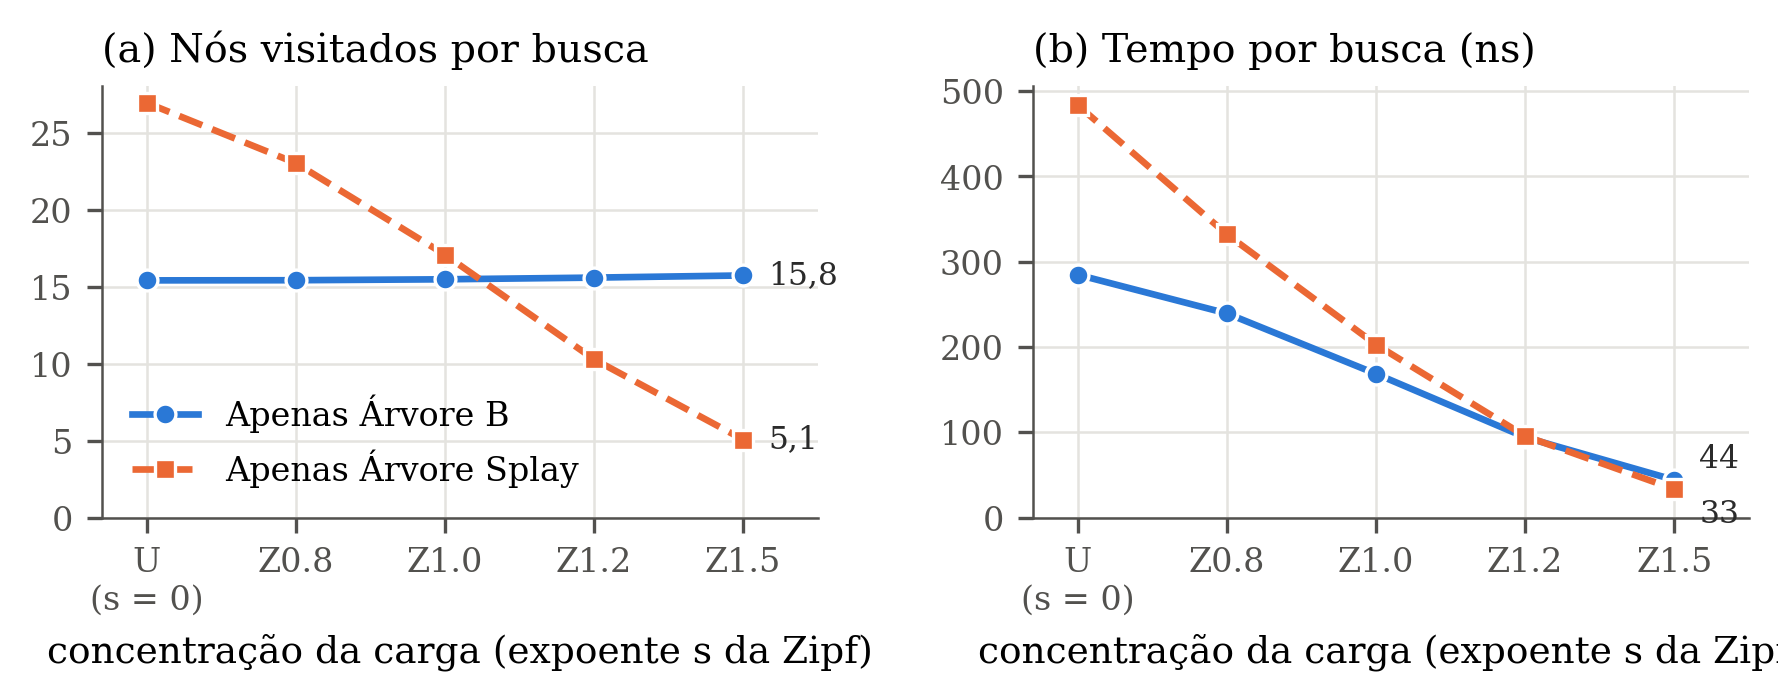

fig2_ganho_teste1.png


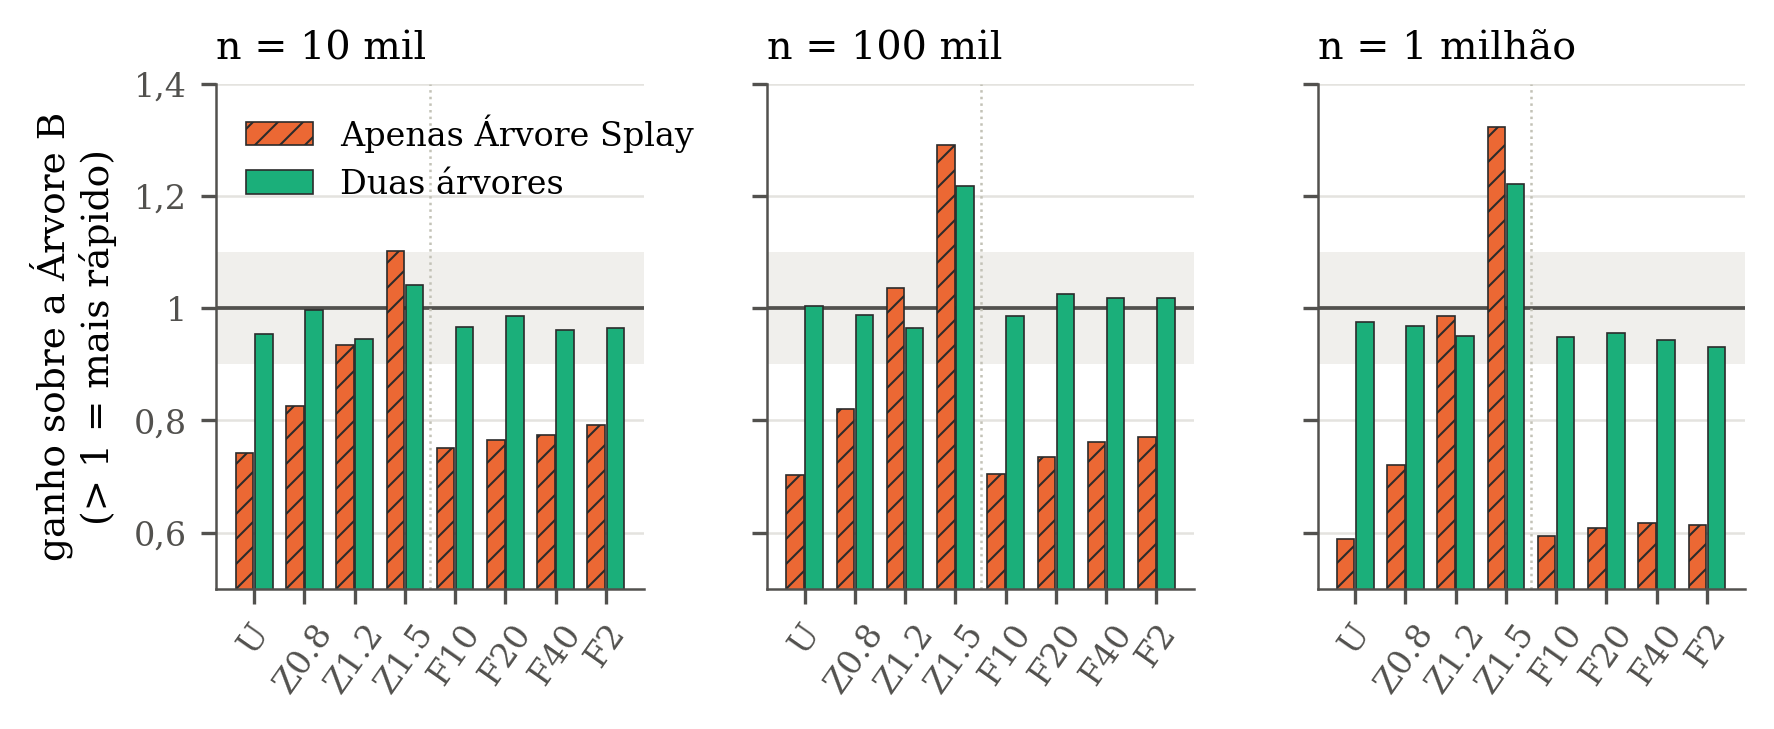

fig3_insercao.png


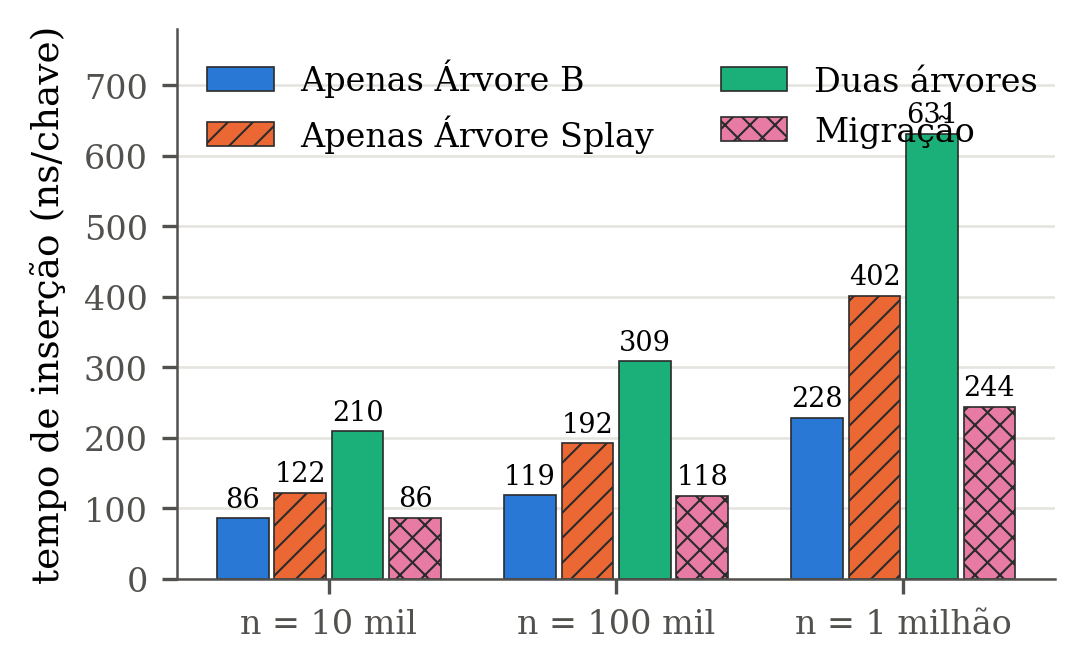

fig4_teste2_limiar.png


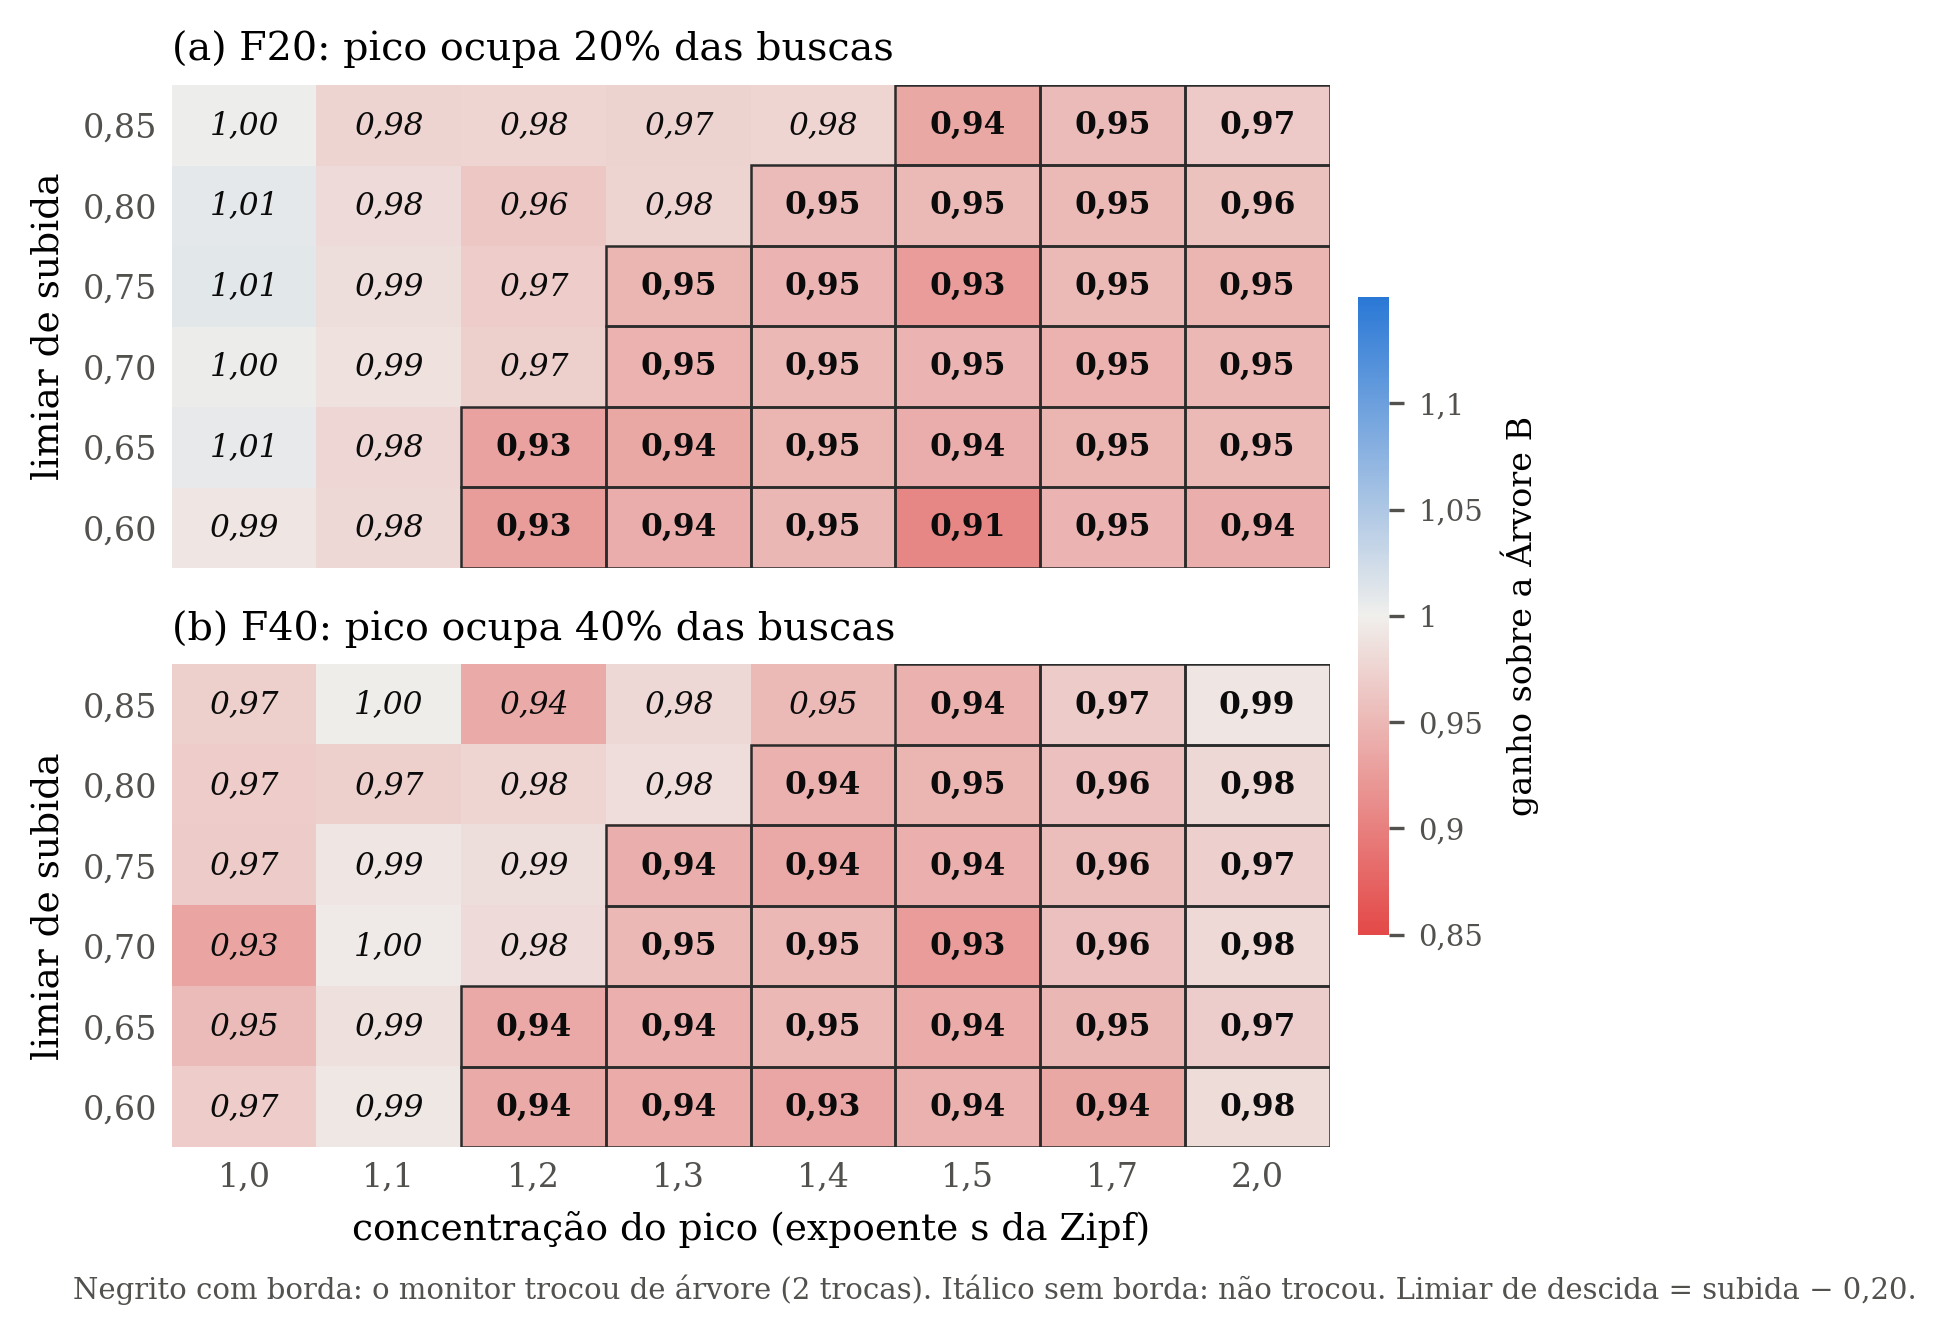

fig5_mista.png


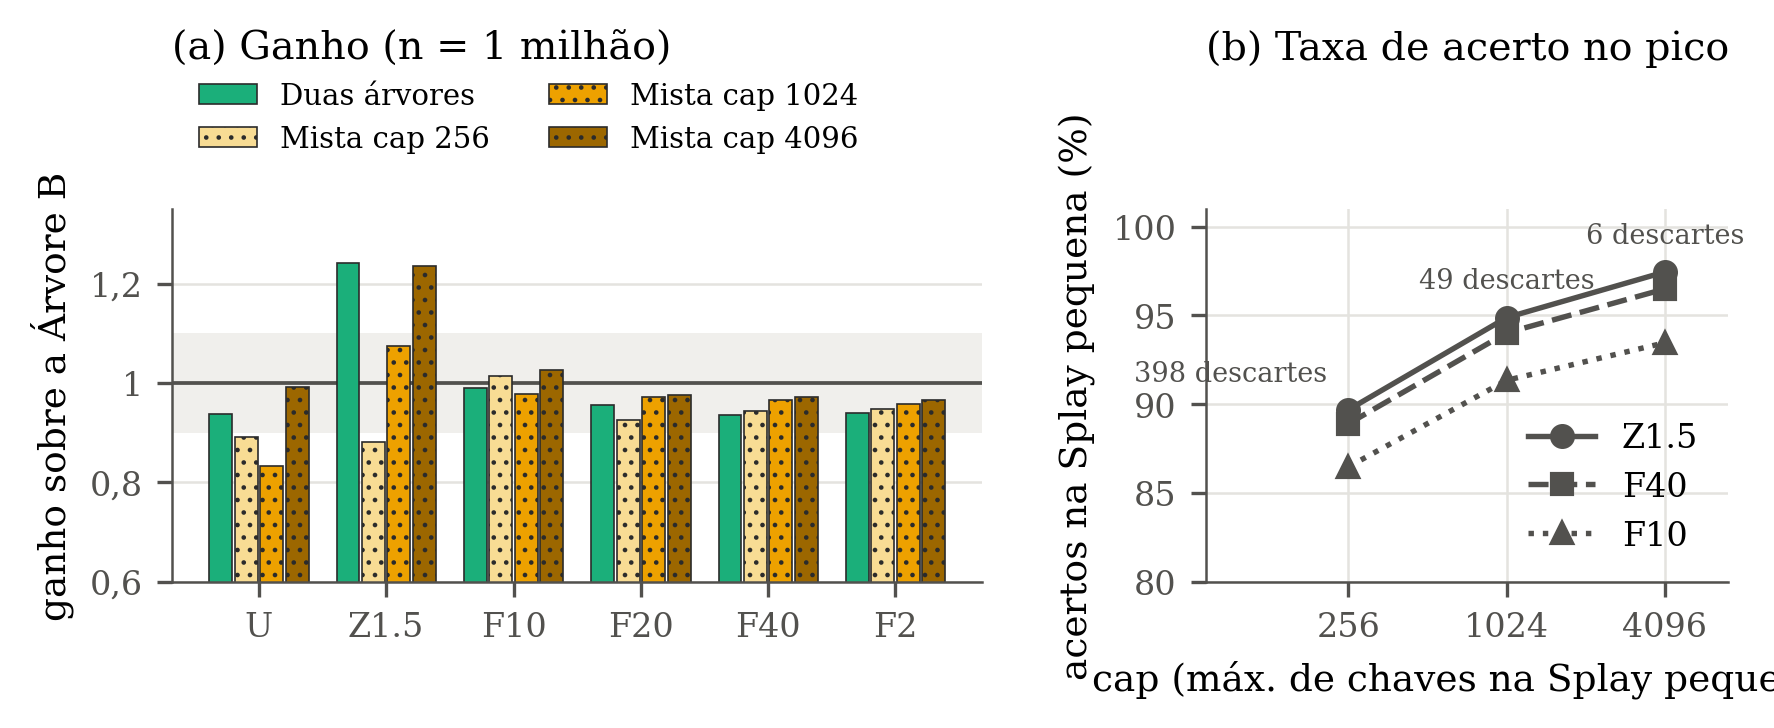

fig6_migracao.png


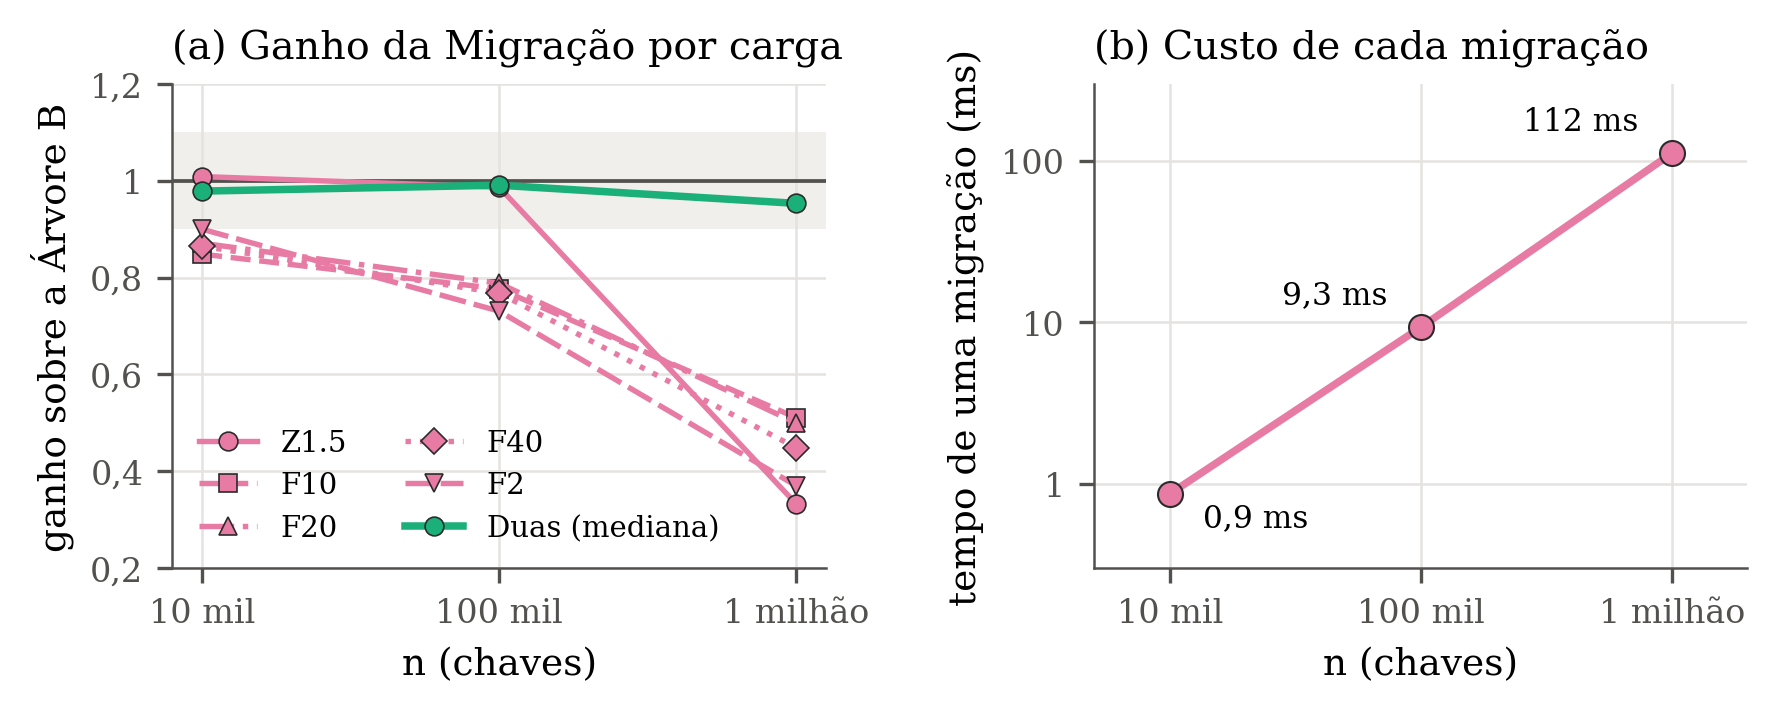

fig7_sem_pico.png


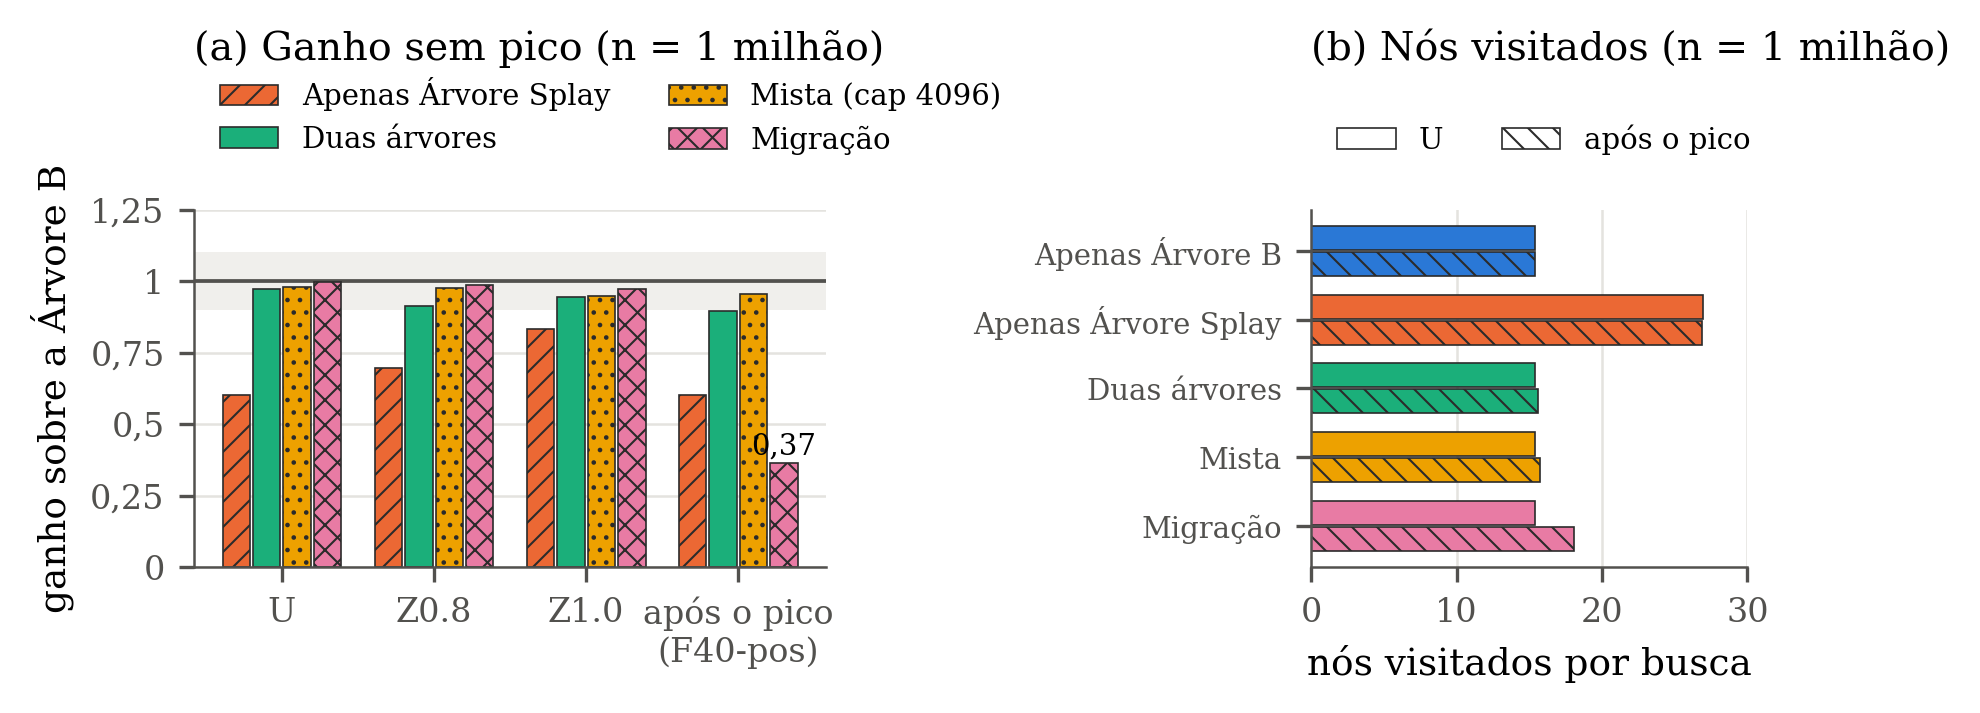

fig8_resumo.png


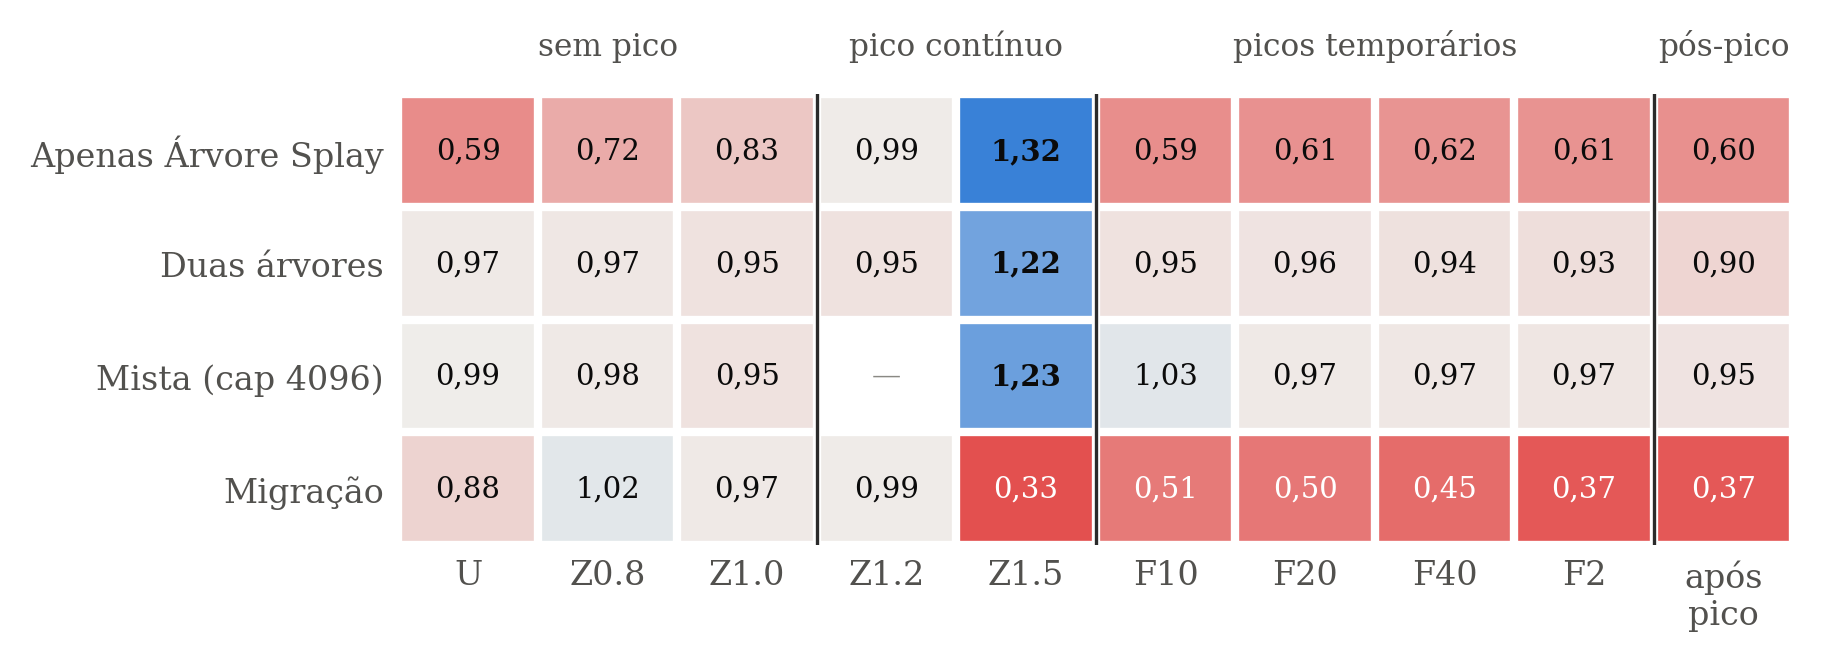

In [4]:

from IPython.display import Image, display
for nome in sorted(f for f in os.listdir("fig") if f.endswith(".png")):
    print(nome)
    display(Image(f"fig/{nome}", width=750))

In [ ]:

!zip -qr figuras.zip fig
files.download("figuras.zip")